The Hub is one quality-assured home for climate data across CGIAR: every
dataset is harmonized to the same metadata standard, openly licensed, and
published in cloud-native formats. In practice that means you find data one
way, judge it one way, and access it one way — whatever the dataset, whatever
your tools. This guide walks that path once, without assuming you write code.


Fetching daily climate data for a region is a small project: find the
boundary, pick a source per variable, respect each server's rate limits,
download, then co-register everything onto one grid. The
`climate-data-download` skill carries that knowledge, so you describe the
result you want and the agent does the steps.

This guide uses [Claude Code](https://claude.com/claude-code) in a terminal.
The skill is a plain Markdown file, so other agents that read skills work
the same way.

## Before you start

- A terminal and Python 3.10 or newer.
- Node.js, for the one-line skill install.
- Disk space near your data, not a synced cloud folder — a few years of
  daily data for one country runs to hundreds of megabytes.

You do not need to write any Python. You do need to read what the agent
proposes before you approve it, which this guide shows you how to do.

## Install the skill

From the folder you want to work in:

```bash
npx skills add https://github.com/CGIAR-Climate-Data-Hub/skills --skill climate-data-download
```

That writes `.agents/skills/climate-data-download/SKILL.md` into the
project. Then install the package the skill drives:

```bash
pip install "aggeodata[download] @ git+https://github.com/CGIAR-Climate-Data-Hub/aggeodata.git" s3fs zarr
```

Start the agent with `claude` in that same folder, and it picks the skill up
automatically.

## Ask for what you need

One sentence is enough, as long as it carries the four things the skill
needs — where, what, when, and where to put it:

> Download daily precipitation and maximum and minimum temperature for
> Ghana, 2020 to 2023, into ../climate/ghana

Leave something out and you will be asked. Say "I don't know" and a
documented default is applied rather than a guess.

Use **no spaces** in the output path. Several tools in the chain pass paths
to subprocesses, and a space in the middle breaks them in ways that surface
much later as a confusing error.

## Read the plan before you approve it

The skill stops and shows its routing before anything downloads. That pause
is the point of the whole design — it is far cheaper to correct a plan than
to re-download three years of data. Check three things:

**The source per variable.** Precipitation comes from CHIRPS, temperature
from CHIRTS, solar radiation from AgERA5. Each is the established choice for
that variable, and each has its own resolution and latency.

**The backend.** `use_zarr: true` reads analysis-ready Zarr stores instead of
fetching one file per day. For a season over a district that is seconds
rather than minutes, and the files written to disk are identical either way.
Expect the agent to propose it.

**The worker count.** With `use_zarr: false`, CHIRPS and CHIRTS must use
`ncores: 1` — `data.chc.ucsb.edu` bans clients that open more than one
connection, and the ban outlasts your session. If you see a plan with
CHIRPS, `use_zarr: false`, and more than one core, stop it.

## What lands on disk

The run writes raw per-variable data, then assembles it into one
co-registered datacube — all variables on the same grid, with the same
dates, named for the region and years it covers. That cube is the thing to
keep: it opens with `xarray` in one line, slices without loading, and is what
the crop-modelling and plotting skills expect as input.

A quick look at what you got:

In [ ]:
import xarray as xr

ds = xr.open_zarr(
    "../pr_gha_2020_2023_raw/chirps_gha_pr_2020.zarr"
)

ds


<xarray.Dataset> Size: 33MB
Dimensions:      (time: 366, lat: 128, lon: 89)
Coordinates:
  * time         (time) datetime64[ns] 3kB 2020-01-01 2020-01-02 ... 2020-12-31
  * lat          (lat) float64 1kB 11.12 11.07 11.02 10.97 ... 4.875 4.825 4.775
  * lon          (lon) float64 712B -3.225 -3.175 -3.125 ... 1.075 1.125 1.175
Data variables:
    pr           (time, lat, lon) float64 33MB dask.array<chunksize=(128, 100, 89), meta=np.ndarray>
    spatial_ref  int32 4B ...
Attributes: (12/15)
    Conventions:          CF-1.10
    title:                aggeodata multi-variable climate datacube
    source:               aggeodata (CHIRPS / CHIRTS / AgERA5 / NASA POWER / ...
    variables:            ['pr']
    time_coverage_start:  2020-01-01
    time_coverage_end:    2020-12-31
    ...                   ...
    geospatial_lat_max:   11.15
    geospatial_lon_min:   -3.25
    geospatial_lon_max:   1.2
    source_product:       chirps
    aoi:                  gha
    year:                 2020

## Visualize your data
The data is stored with time, longitude, and latitude dimensions. You can plot individual data by selecting a specific time, or by applying a spatial average to plot a time series over a region.

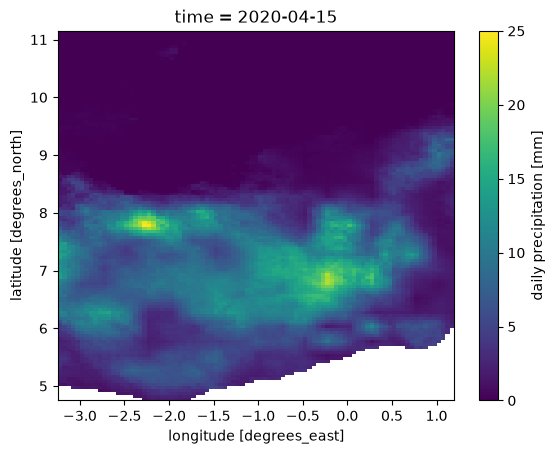

In [7]:
ds.isel(time = 105).pr.plot()

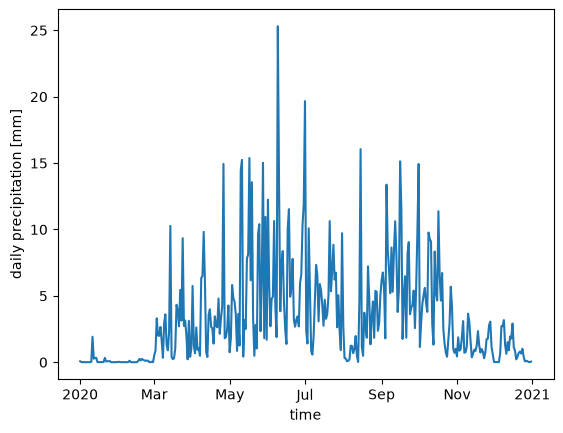

In [11]:
ds["pr"].mean(dim=["lat", "lon"]).plot()


Check the obvious things. Do the variables match what you asked for? Does
the time axis start and end where it should? Is the bounding box your region
rather than the whole country?

## Two things that will catch you out

**AgERA5 needs a CDS key.** Solar radiation, humidity, wind, and dew point
route through the Copernicus Climate Data Store, which needs a free account
and a `~/.cdsapirc` file. If no solar radiation appears in your request, this
never comes up — so it surprises people the first time they add `rsds`.

**Zarr means three different things** in the config: which backend reads the
source, what the download step leaves on disk, and how the final cube is
written. They are independent settings. The agent sets all three
consistently; it is worth knowing they exist when you read a config later
and wonder why one says `netcdf` and another says `zarr`.

## Where next

- [Soil data](https://cgiar-climate-data-hub.github.io/skills/skills/soil-data-download/)
  — SoilGrids on the same pattern, and the other half of a crop-model input set.
- [Spatial crop modelling](https://cgiar-climate-data-hub.github.io/skills/skills/spatial-crop-modeler/)
  — run DSSAT over a region using the cube you just built.
- [All CDH skills](https://cgiar-climate-data-hub.github.io/skills/) — the
  full set, each installable the same way.
- Stuck? [Open an issue](/contribute/#report) and the team will pick it up.